# 05 — Diffusion Models for Robot Policies

In this notebook, we explore **diffusion models** as a generative approach
for learning multimodal action distributions in robot learning.

In previous notebooks, we studied:
- **Behavior Cloning:** deterministic policies trained with MSE can average
  different valid actions.
- **Mixture Density Networks:** explicitly represent multiple modes using
  a mixture of Gaussian distributions.
- **Action Chunking:** predict sequences of actions to capture temporal
  dependencies.
- **Conditional VAE:** generate multimodal action chunks using latent variables.

Diffusion models offer a different approach: instead of generating actions
through a latent decoder, they learn to transform Gaussian noise into
samples from the data distribution through an iterative denoising process.

## Learning objectives

By the end of this notebook, we will:

1. Understand the **forward diffusion process** and noise schedules.
2. Implement a neural network that predicts noise at different diffusion timesteps.
3. Implement the **reverse diffusion process (DDPM sampling)**.
4. Generate samples from a bimodal 2D distribution.
5. Extend diffusion to **conditional generation** using robot observations.
6. Generate **action chunks** with a diffusion policy.
7. Evaluate the policy through closed-loop rollouts and compare it with
   previous approaches (MDN and CVAE).

## Key question

**How can a neural network learn to generate coherent, multimodal action
sequences by progressively transforming Gaussian noise into actions?**

We start with a simple 2D distribution and progressively build a
conditional diffusion policy for our PointRobot environment.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import torch

torch.manual_seed(42)
np.random.seed(42)

In [5]:
n_samples = 5000

means = torch.tensor([
    [-2.0, 0.0],
    [ 2.0, 0.0],
])

std = 0.3

modes = torch.randint(
    low=0,
    high=2,
    size=(n_samples,),
)

x0 = means[modes] + std * torch.randn(
    n_samples, 2
)

print(x0.shape)

torch.Size([5000, 2])


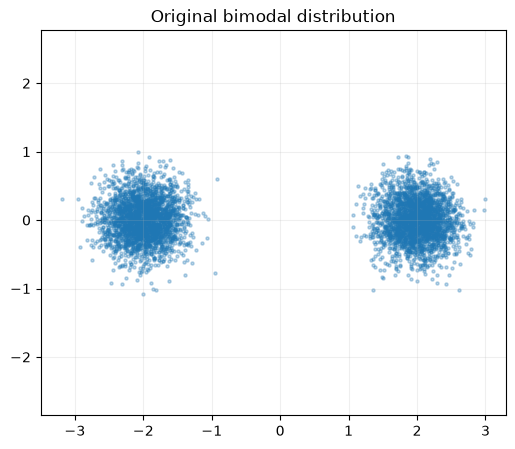

In [6]:
plt.figure(figsize=(6, 5))

plt.scatter(
    x0[:, 0],
    x0[:, 1],
    s=5,
    alpha=0.3,
)

plt.axis("equal")
plt.title("Original bimodal distribution")
plt.grid(alpha=0.2)
plt.show()

### Forward diffusion

In [7]:
T = 100

betas = torch.linspace(
    1e-4,
    0.1,
    T,
)

alphas = 1.0 - betas

alpha_bars = torch.cumprod(
    alphas,
    dim=0,
)

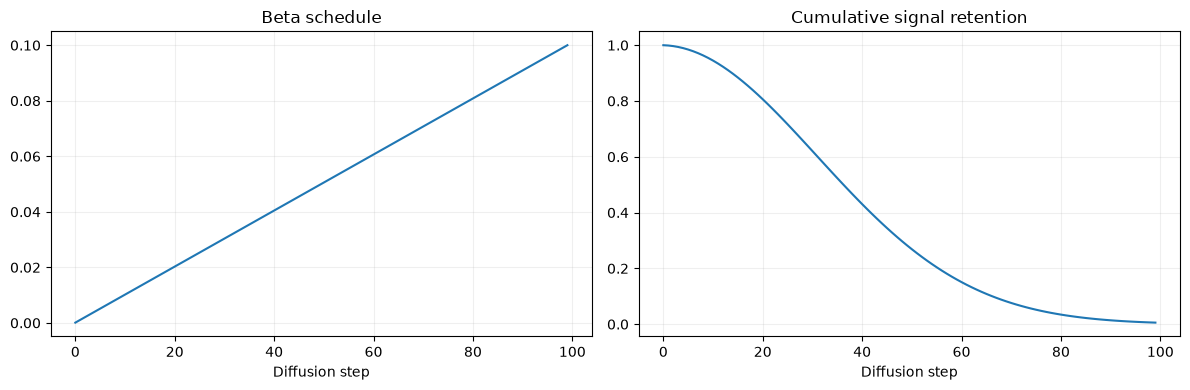

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(betas)
axes[0].set_title("Beta schedule")
axes[0].set_xlabel("Diffusion step")

axes[1].plot(alpha_bars)
axes[1].set_title("Cumulative signal retention")
axes[1].set_xlabel("Diffusion step")

for ax in axes:
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [9]:
def forward_diffusion(x0, t, alpha_bars):
    """
    x0: (N, 2)
    t: integer timestep, 0-based
    """
    alpha_bar = alpha_bars[t]

    noise = torch.randn_like(x0)

    xt = (
        torch.sqrt(alpha_bar) * x0
        + torch.sqrt(1 - alpha_bar) * noise
    )

    return xt

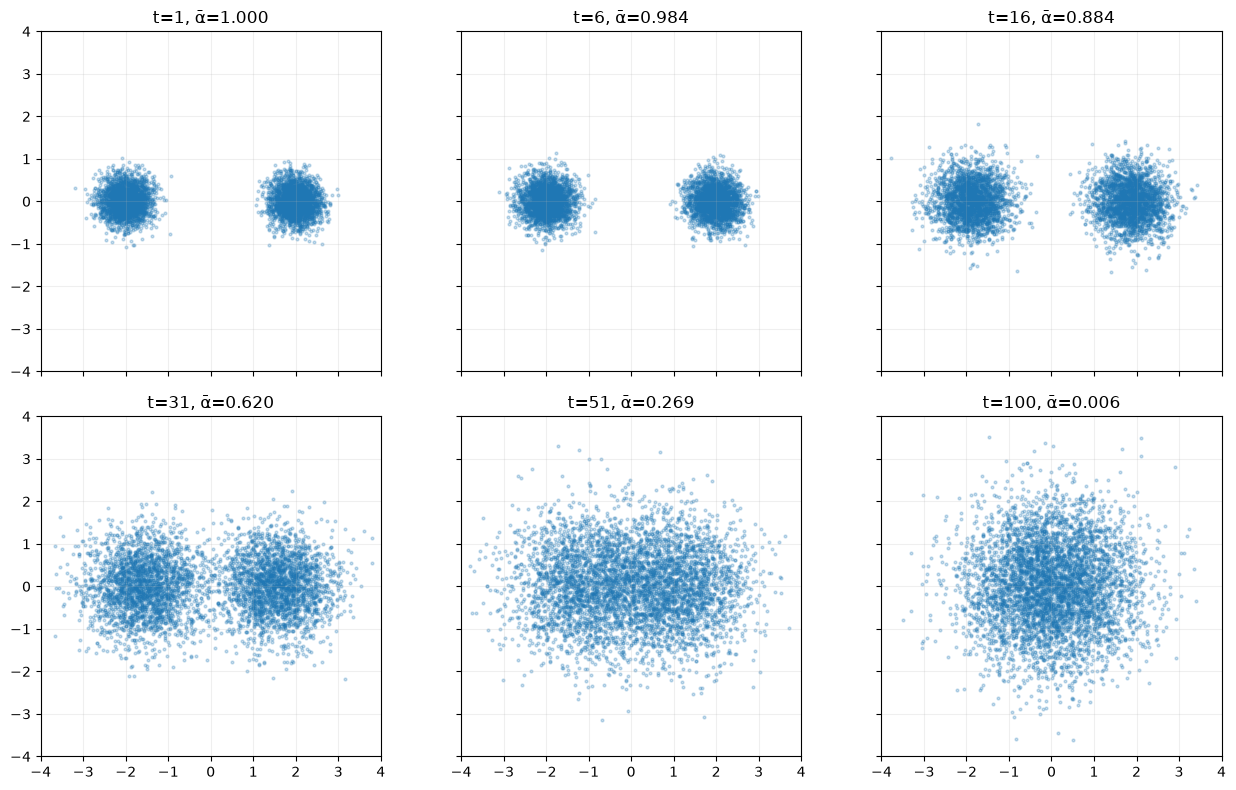

In [10]:
timesteps = [0, 5, 15, 30, 50, 99]

fig, axes = plt.subplots(
    2, 3,
    figsize=(13, 8),
    sharex=True,
    sharey=True,
)

for ax, t in zip(axes.flat, timesteps):
    xt = forward_diffusion(
        x0,
        t,
        alpha_bars,
    )

    ax.scatter(
        xt[:, 0],
        xt[:, 1],
        s=4,
        alpha=0.25,
    )

    ax.set_title(
        f"t={t+1}, ᾱ={alpha_bars[t]:.3f}"
    )

    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

What happens to a single data point in the forward diffusion process?

In [11]:
x_single = x0[0:1]

trajectory = [x_single.squeeze(0)]

x = x_single.clone()

for t in range(T):
    noise = torch.randn_like(x)

    x = (
        torch.sqrt(alphas[t]) * x
        + torch.sqrt(betas[t]) * noise
    )

    trajectory.append(x.squeeze(0))

trajectory = torch.stack(trajectory)

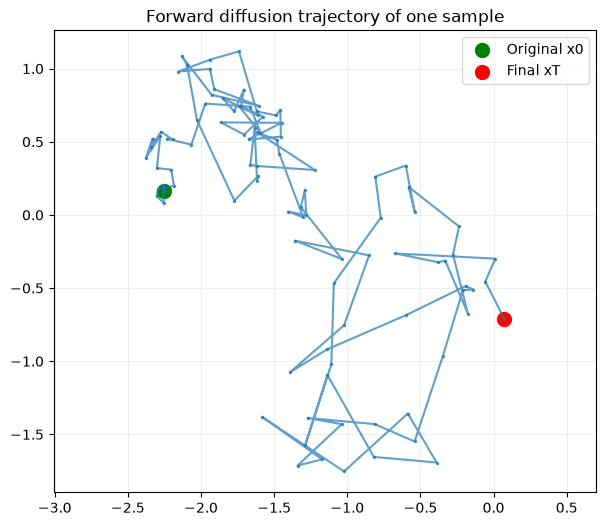

In [12]:
plt.figure(figsize=(7, 6))

plt.plot(
    trajectory[:, 0],
    trajectory[:, 1],
    marker=".",
    markersize=3,
    alpha=0.7,
)

plt.scatter(
    *trajectory[0],
    color="green",
    s=100,
    label="Original x0",
)

plt.scatter(
    *trajectory[-1],
    color="red",
    s=100,
    label="Final xT",
)

plt.axis("equal")
plt.title("Forward diffusion trajectory of one sample")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Learning to predict noise

The forward diffusion process gradually corrupts data with Gaussian noise.

We now train a neural network to predict the noise added to a sample:

$$
\epsilon_\theta(x_t,t)\approx\epsilon
$$

The network receives:
- A noisy sample \($x_t$\).
- The diffusion timestep \(t\), indicating the noise level.

The training objective is:

$$
\mathcal{L}_{\mathrm{noise}}=
\mathbb{E}_{x_0,t,\epsilon}
\left[\|\epsilon-\epsilon_\theta(x_t,t)\|^2\right]
$$

Unlike deterministic Behavior Cloning, where MSE directly predicts an
action, here MSE trains a model to estimate the noise contaminating a
sample at a particular diffusion timestep.

This is the foundation of **denoising diffusion probabilistic models (DDPMs)**.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class NoisePredictor(nn.Module):
    def __init__(self, hidden_dim=128):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(3, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 2),
        )

    def forward(self, xt, t):
        # xt: (batch_size, 2)
        # t:  (batch_size,) with values in [0, T-1]

        t_normalized = t.float().unsqueeze(-1) / (T - 1)

        network_input = torch.cat(
            [xt, t_normalized],
            dim=-1,
        )

        return self.net(network_input)

As training data we do not need to pre-generate a dataset of noisy sample. At each iteration:

- Sample original data $x_0$
- Sample random timestep t
- Generate gaussian noise $\epsilon$
- Compute $x_t$ with forward diffusion
- Train NN to predict added noise

The same data $x_0$ is seen in training with different levels of noise


In [14]:
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

model = NoisePredictor().to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
)

x0_train = x0.to(device)
alpha_bars_device = alpha_bars.to(device)

batch_size = 256
n_steps = 5000

losses = []

In [15]:
model.train()

for step_idx in range(n_steps):

    # 1. Sample clean data
    indices = torch.randint(
        0,
        len(x0_train),
        (batch_size,),
        device=device,
    )
    clean = x0_train[indices]

    # 2. Sample diffusion timesteps
    t = torch.randint(
        0,
        T,
        (batch_size,),
        device=device,
    )

    # 3. Sample Gaussian noise
    noise = torch.randn_like(clean)

    # 4. Apply forward diffusion
    alpha_bar = alpha_bars_device[t].unsqueeze(-1)

    noisy = (
        torch.sqrt(alpha_bar) * clean
        + torch.sqrt(1 - alpha_bar) * noise
    )

    # 5. Predict noise
    predicted_noise = model(noisy, t)

    # 6. Noise prediction loss
    loss = F.mse_loss(predicted_noise, noise)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if (step_idx + 1) % 500 == 0:
        print(
            f"Step {step_idx + 1:4d}/{n_steps} "
            f"| Loss: {loss.item():.4f}"
        )

Step  500/5000 | Loss: 0.2765
Step 1000/5000 | Loss: 0.2916
Step 1500/5000 | Loss: 0.2643
Step 2000/5000 | Loss: 0.2584
Step 2500/5000 | Loss: 0.3184
Step 3000/5000 | Loss: 0.2432
Step 3500/5000 | Loss: 0.2490
Step 4000/5000 | Loss: 0.3345
Step 4500/5000 | Loss: 0.2497
Step 5000/5000 | Loss: 0.2788


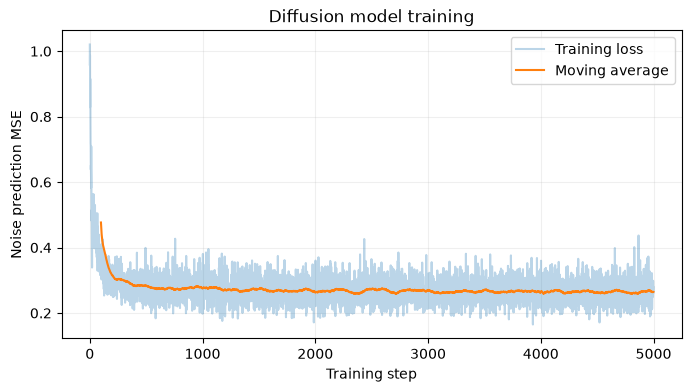

In [16]:
plt.figure(figsize=(8, 4))

plt.plot(losses, alpha=0.3, label="Training loss")

window = 100

smoothed = np.convolve(
    losses,
    np.ones(window) / window,
    mode="valid",
)

plt.plot(
    np.arange(window - 1, len(losses)),
    smoothed,
    label="Moving average",
)

plt.xlabel("Training step")
plt.ylabel("Noise prediction MSE")
plt.title("Diffusion model training")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Estimating the original sample

Once the network predicts the noise, we can estimate the original
clean sample by rearranging the forward diffusion equation:

$$
\hat{x}_0 =
\frac{x_t-\sqrt{1-\bar{\alpha}_t}\epsilon_\theta(x_t,t)}
{\sqrt{\bar{\alpha}_t}}
$$

This provides a useful diagnostic of what the network has learned.

However, predicting \(\hat{x}_0\) from a noisy sample is not yet the
complete reverse diffusion process. At high noise levels, a single
estimate can be ambiguous.

In the next section, we will use the noise predictor iteratively
to generate new samples from Gaussian noise.

In [17]:
model.eval()

t_test = 30
n_test = 500

with torch.no_grad():
    clean = x0_train[:n_test]

    noise = torch.randn_like(clean)

    alpha_bar = alpha_bars_device[t_test]

    noisy = (
        torch.sqrt(alpha_bar) * clean
        + torch.sqrt(1 - alpha_bar) * noise
    )

    t_batch = torch.full(
        (n_test,),
        t_test,
        dtype=torch.long,
        device=device,
    )

    predicted_noise = model(noisy, t_batch)

    x0_pred = (
        noisy
        - torch.sqrt(1 - alpha_bar) * predicted_noise
    ) / torch.sqrt(alpha_bar)

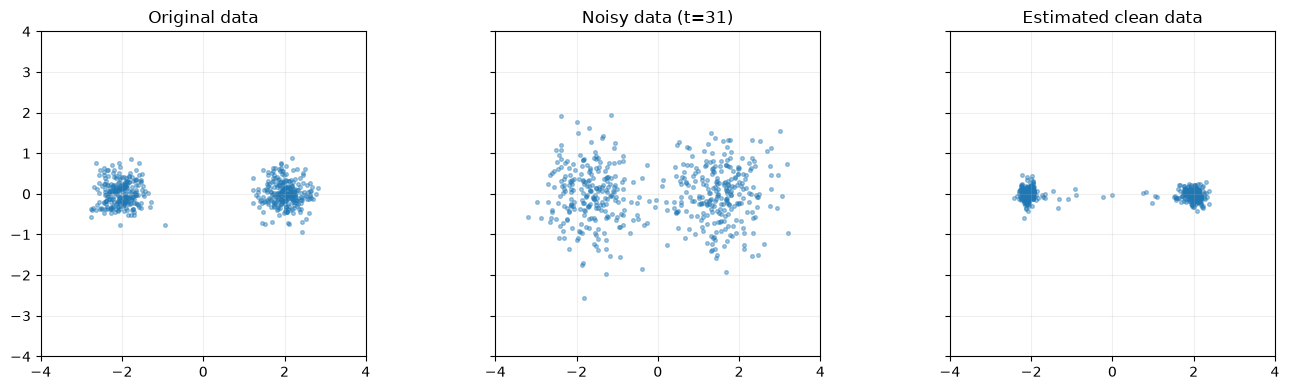

In [18]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(14, 4),
    sharex=True,
    sharey=True,
)

datasets = [
    clean.cpu(),
    noisy.cpu(),
    x0_pred.cpu(),
]

titles = [
    "Original data",
    f"Noisy data (t={t_test + 1})",
    "Estimated clean data",
]

for ax, data, title in zip(axes, datasets, titles):
    ax.scatter(
        data[:, 0],
        data[:, 1],
        s=7,
        alpha=0.4,
    )

    ax.set_title(title)
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Reverse diffusion: DDPM sampling

We have trained a neural network to predict the noise added to a sample
at any diffusion timestep.

We can now use this network to generate new samples.

Starting from Gaussian noise:

$$
x_T \sim \mathcal{N}(0,I)
$$

we iteratively apply a learned reverse transition:

$$
p_\theta(x_{t-1}\mid x_t)
=
\mathcal{N}(\mu_\theta(x_t,t),\tilde{\beta}_t I)
$$

where:

$$
\mu_\theta(x_t,t)=
\frac{1}{\sqrt{\alpha_t}}
\left(
x_t-\frac{\beta_t}{\sqrt{1-\bar{\alpha}_t}}
\epsilon_\theta(x_t,t)
\right)
$$

The key idea is that a sequence of relatively simple denoising steps
can generate samples from a complex, multimodal distribution.

Unlike the previous experiment, we do not start from a noisy version
of a known data point. We start from completely new Gaussian noise.

In [19]:
@torch.no_grad()
def ddpm_sample(model, n_samples=2000):
    model.eval()

    # Start from Gaussian noise
    x = torch.randn(n_samples, 2, device=device)

    # Store intermediate samples for visualization
    history = {T: x.cpu().clone()}

    for t in reversed(range(T)):

        t_batch = torch.full(
            (n_samples,),
            t,
            device=device,
            dtype=torch.long,
        )

        # Predict noise
        predicted_noise = model(x, t_batch)

        alpha = alphas[t].to(device)
        beta = betas[t].to(device)
        alpha_bar = alpha_bars[t].to(device)

        # Reverse process mean
        mean = (
            x
            - beta / torch.sqrt(1 - alpha_bar)
            * predicted_noise
        ) / torch.sqrt(alpha)

        if t > 0:
            alpha_bar_prev = alpha_bars[t - 1].to(device)

            posterior_variance = (
                beta
                * (1 - alpha_bar_prev)
                / (1 - alpha_bar)
            )

            noise = torch.randn_like(x)

            x = mean + torch.sqrt(posterior_variance) * noise
        else:
            x = mean

        if t in [79, 59, 39, 19, 0]:
            history[t] = x.cpu().clone()

    return x.cpu(), history

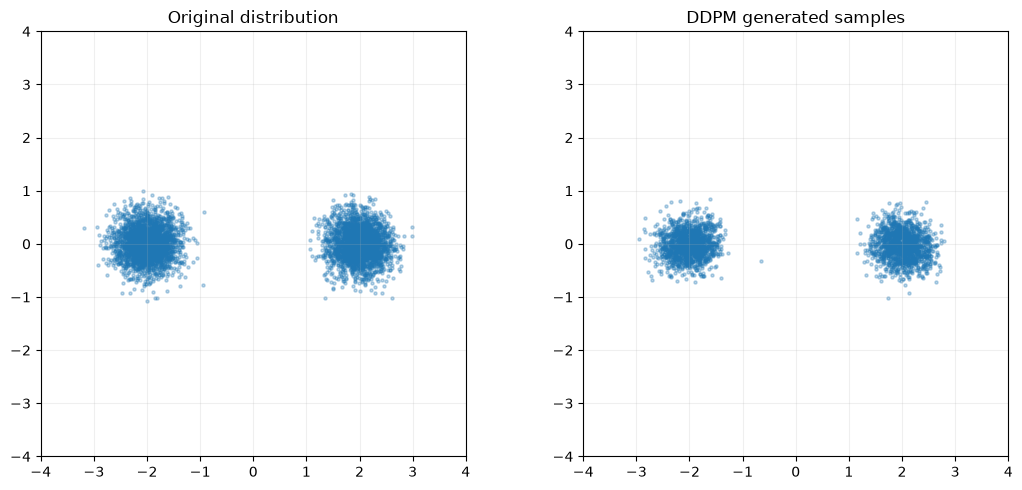

In [20]:
generated, history = ddpm_sample(
    model,
    n_samples=3000,
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 5),
)

axes[0].scatter(
    x0[:, 0],
    x0[:, 1],
    s=5,
    alpha=0.3,
)

axes[0].set_title("Original distribution")

axes[1].scatter(
    generated[:, 0],
    generated[:, 1],
    s=5,
    alpha=0.3,
)

axes[1].set_title("DDPM generated samples")

for ax in axes:
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

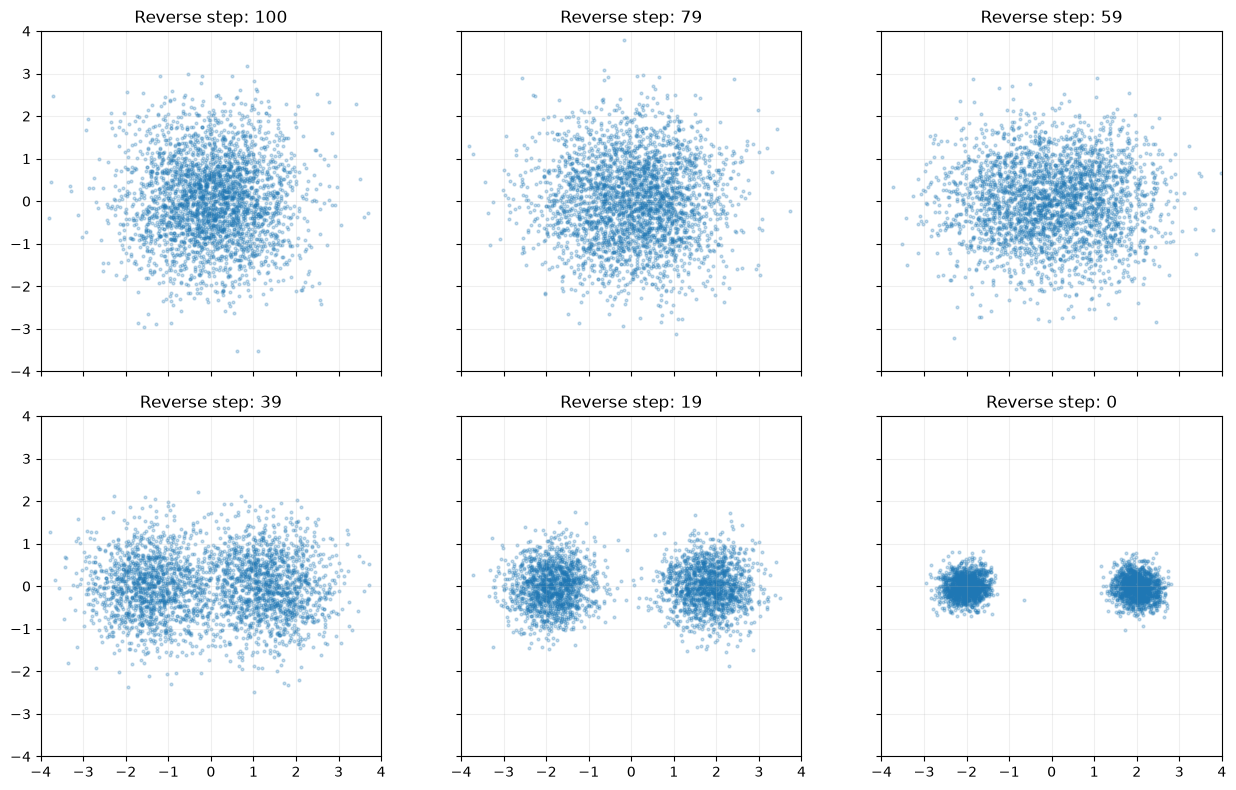

In [21]:
steps = [100, 79, 59, 39, 19, 0]

fig, axes = plt.subplots(
    2, 3,
    figsize=(13, 8),
    sharex=True,
    sharey=True,
)

for ax, t in zip(axes.flat, steps):

    samples = history[t]

    ax.scatter(
        samples[:, 0],
        samples[:, 1],
        s=4,
        alpha=0.25,
    )

    ax.set_title(f"Reverse step: {t}")

    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Conditional Diffusion for Robot Actions

So far, our diffusion model has learned an unconditional distribution:

\[
p_\theta(x)
\]

For robot learning, we need to generate actions conditioned on the
current observation:

$$
\pi_\theta(a_t \mid o_t)
$$

We therefore train a conditional noise predictor:

$$
\epsilon_\theta(a_t^{(k)}, k, o_t)
$$

where \(k\) is the diffusion timestep and \(t\) is the robot timestep.

During training, we add Gaussian noise to the expert actions and
train the network to predict that noise using the noisy action,
the diffusion timestep, and the observation.

During inference, we start from Gaussian noise and iteratively
denoise it while keeping the robot observation fixed.

Our first goal is to generate **single actions**, before extending
the model to action chunks.

In [22]:
from robot_learning_playground.point_robot import collect_demonstrations
from torch.utils.data import TensorDataset, DataLoader

# Reuse the expert demonstration dataset from previous notebooks.
# Each observation must be paired with its expert action.

demonstrations = collect_demonstrations(
    n_episodes=500,
    seed=42,
)

observations = np.concatenate([
    demo["observations"]
    for demo in demonstrations
])

actions = np.concatenate([
    demo["actions"]
    for demo in demonstrations
])

observations = torch.as_tensor(
    observations,
    dtype=torch.float32,
)

actions = torch.as_tensor(
    actions,
    dtype=torch.float32,
)

assert observations.ndim == 2
assert actions.ndim == 2
assert actions.shape[1] == 2
assert len(observations) == len(actions)

obs_dim = observations.shape[1]
action_dim = actions.shape[1]

print("Observations:", observations.shape)
print("Actions:", actions.shape)

Observations: torch.Size([12768, 4])
Actions: torch.Size([12768, 2])


In [23]:
# Normalize the actions to have zero mean and unit variance.

action_mean = actions.mean(dim=0)
action_std = actions.std(dim=0).clamp_min(1e-6)

actions_normalized = (
    actions - action_mean
) / action_std

print("Action mean:", action_mean)
print("Action std:", action_std)

Action mean: tensor([-1.7981e-05,  3.9160e-02])
Action std: tensor([0.0280, 0.0068])


In [24]:
class ConditionalNoisePredictor(nn.Module):
    def __init__(self, obs_dim, action_dim=2, hidden_dim=128):
        super().__init__()

        input_dim = action_dim + obs_dim + 1

        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, action_dim),
        )

    def forward(self, noisy_action, k, observation):
        k_normalized = (
            k.float().unsqueeze(-1) / (T - 1)
        )

        x = torch.cat(
            [noisy_action, observation, k_normalized],
            dim=-1,
        )

        return self.net(x)

In [25]:
conditional_model = ConditionalNoisePredictor(
    obs_dim=obs_dim,
    action_dim=action_dim,
).to(device)

optimizer = torch.optim.Adam(
    conditional_model.parameters(),
    lr=1e-3,
)

obs_train = observations.to(device)
act_train = actions_normalized.to(device)

conditional_losses = []

n_steps = 5000
batch_size = 256

In [26]:
conditional_model.train()

for step_idx in range(n_steps):

    indices = torch.randint(
        0,
        len(obs_train),
        (batch_size,),
        device=device,
    )

    obs_batch = obs_train[indices]
    clean_actions = act_train[indices]

    # Random diffusion timestep
    k = torch.randint(
        0,
        T,
        (batch_size,),
        device=device,
    )

    # Forward diffusion on expert actions
    noise = torch.randn_like(clean_actions)

    alpha_bar = alpha_bars_device[k].unsqueeze(-1)

    noisy_actions = (
        torch.sqrt(alpha_bar) * clean_actions
        + torch.sqrt(1 - alpha_bar) * noise
    )

    # Conditional noise prediction
    predicted_noise = conditional_model(
        noisy_actions,
        k,
        obs_batch,
    )

    loss = F.mse_loss(predicted_noise, noise)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    conditional_losses.append(loss.item())

    if (step_idx + 1) % 500 == 0:
        print(
            f"Step {step_idx + 1}/{n_steps}"
            f" | Loss: {loss.item():.4f}"
        )

Step 500/5000 | Loss: 0.2293
Step 1000/5000 | Loss: 0.1767
Step 1500/5000 | Loss: 0.1796
Step 2000/5000 | Loss: 0.1784
Step 2500/5000 | Loss: 0.1634
Step 3000/5000 | Loss: 0.1545
Step 3500/5000 | Loss: 0.0925
Step 4000/5000 | Loss: 0.0985
Step 4500/5000 | Loss: 0.1106
Step 5000/5000 | Loss: 0.1113


In [27]:
@torch.no_grad()
def conditional_ddpm_sample(model, observation, n_samples=100):
    model.eval()

    obs = torch.as_tensor(
        observation,
        dtype=torch.float32,
        device=device,
    ).reshape(1, -1)

    obs = obs.expand(n_samples, -1)

    # Initial Gaussian noise in normalized action space
    x = torch.randn(
        n_samples,
        action_dim,
        device=device,
    )

    for k in reversed(range(T)):

        k_batch = torch.full(
            (n_samples,),
            k,
            dtype=torch.long,
            device=device,
        )

        predicted_noise = model(
            x,
            k_batch,
            obs,
        )

        alpha = alphas[k].to(device)
        beta = betas[k].to(device)
        alpha_bar = alpha_bars[k].to(device)

        mean = (
            x
            - beta / torch.sqrt(1 - alpha_bar)
            * predicted_noise
        ) / torch.sqrt(alpha)

        if k > 0:
            alpha_bar_prev = alpha_bars[k - 1].to(device)

            posterior_variance = (
                beta
                * (1 - alpha_bar_prev)
                / (1 - alpha_bar)
            )

            x = (
                mean
                + torch.sqrt(posterior_variance)
                * torch.randn_like(x)
            )
        else:
            x = mean

    # Convert back to robot action units
    action_mean_device = action_mean.to(device)
    action_std_device = action_std.to(device)

    generated_actions = (
        x * action_std_device
        + action_mean_device
    )

    return generated_actions.cpu()

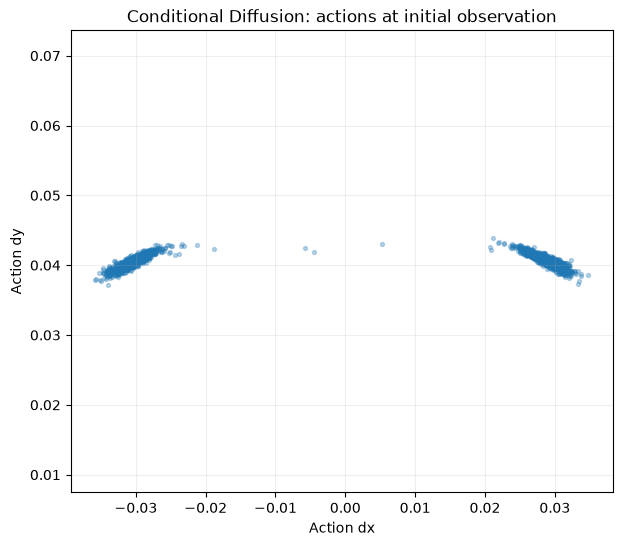

In [30]:
from robot_learning_playground.point_robot import make_observation

start = np.array([0.0, 0.0])
goal = np.array([0.0, 1.0])

initial_observation = make_observation(start, goal)

generated_actions = conditional_ddpm_sample(
    conditional_model,
    initial_observation,
    n_samples=2000,
)

plt.figure(figsize=(7, 6))

plt.scatter(
    generated_actions[:, 0],
    generated_actions[:, 1],
    s=8,
    alpha=0.3,
)

plt.xlabel("Action dx")
plt.ylabel("Action dy")
plt.title("Conditional Diffusion: actions at initial observation")
plt.axis("equal")
plt.grid(alpha=0.2)
plt.show()

## Closed-loop evaluation of a single-action diffusion policy

Our conditional diffusion model can generate multimodal actions given
a robot observation.

However, generating plausible individual actions does not guarantee
successful robot behavior.

We now evaluate the policy in closed-loop:

1. Observe the current robot state.
2. Sample one action using conditional DDPM.
3. Execute the action in the environment.
4. Repeat using the updated observation.

Since each action is generated independently, the policy may switch
between different strategies during execution.

We evaluate:
- Success rate
- Collision rate
- Robot trajectories
- Consistency of the generated actions

This experiment motivates the use of action chunking in Diffusion Policy.

In [32]:
from robot_learning_playground.point_robot import make_observation, step, is_collision

@torch.no_grad()
def diffusion_policy_action(observation):
    action = conditional_ddpm_sample(
        conditional_model,
        observation,
        n_samples=1,
    )

    return action[0].numpy()

In [33]:
def rollout_diffusion_policy(
    start,
    goal,
    max_steps=100,
    goal_tolerance=0.05,
):
    position = np.asarray(start, dtype=float).copy()
    goal = np.asarray(goal, dtype=float)

    positions = [position.copy()]
    actions = []

    success = False
    collision = False

    for _ in range(max_steps):

        observation = make_observation(position, goal)

        action = diffusion_policy_action(observation)

        next_position = step(position, action)

        actions.append(action.copy())
        positions.append(np.asarray(next_position).copy())

        position = np.asarray(next_position).copy()

        if is_collision(position):
            collision = True
            break

        if np.linalg.norm(position - goal) < goal_tolerance:
            success = True
            break

    return {
        "positions": np.asarray(positions),
        "actions": np.asarray(actions),
        "success": success,
        "collision": collision,
    }

In [34]:
n_rollouts = 10

rollouts = [
    rollout_diffusion_policy(start, goal)
    for _ in range(n_rollouts)
]

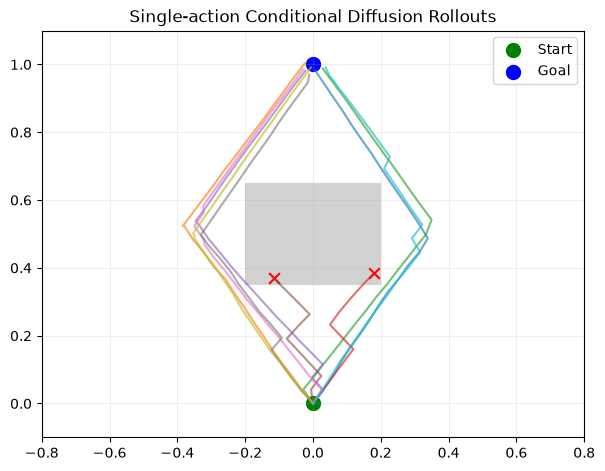

In [35]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(7, 7))

obstacle = Rectangle(
    (-0.2, 0.35),
    0.4,
    0.3,
    facecolor="gray",
    alpha=0.35,
)

ax.add_patch(obstacle)

for rollout in rollouts:
    positions = rollout["positions"]

    ax.plot(
        positions[:, 0],
        positions[:, 1],
        alpha=0.65,
    )

    if rollout["collision"]:
        ax.scatter(
            *positions[-1],
            color="red",
            marker="x",
            s=60,
        )

ax.scatter(*start, color="green", s=100, label="Start")
ax.scatter(*goal, color="blue", s=100, label="Goal")

ax.set_xlim(-0.8, 0.8)
ax.set_ylim(-0.1, 1.1)
ax.set_aspect("equal")
ax.set_title("Single-action Conditional Diffusion Rollouts")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

In [36]:
n_eval = 100

evaluation = [
    rollout_diffusion_policy(start, goal)
    for _ in range(n_eval)
]

success_rate = np.mean([
    r["success"] for r in evaluation
])

collision_rate = np.mean([
    r["collision"] for r in evaluation
])

timeout_rate = np.mean([
    not r["success"] and not r["collision"]
    for r in evaluation
])

print(f"Success rate:   {success_rate:.1%}")
print(f"Collision rate: {collision_rate:.1%}")
print(f"Timeout rate:   {timeout_rate:.1%}")

Success rate:   68.0%
Collision rate: 32.0%
Timeout rate:   0.0%


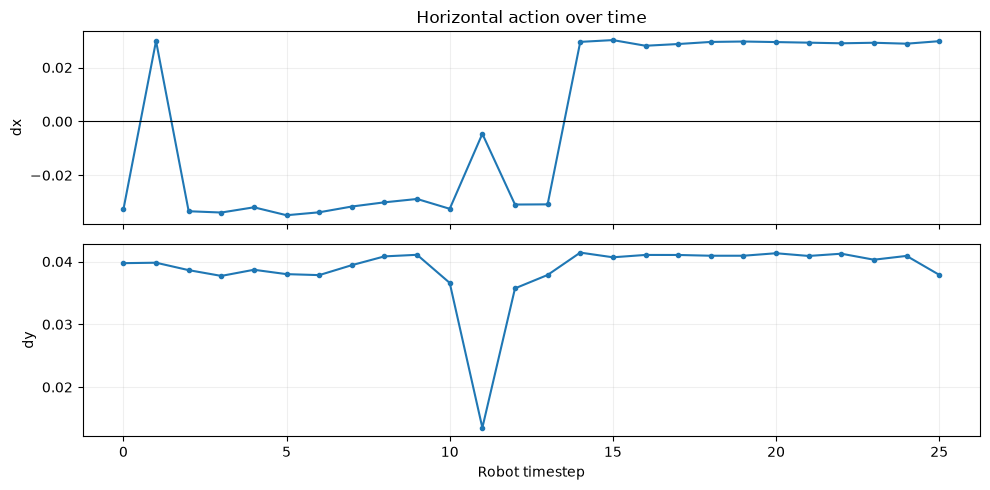

In [37]:
example = evaluation[0]

actions_history = example["actions"]

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

axes[0].plot(
    actions_history[:, 0],
    marker=".",
)

axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("dx")
axes[0].set_title("Horizontal action over time")

axes[1].plot(
    actions_history[:, 1],
    marker=".",
)

axes[1].set_ylabel("dy")
axes[1].set_xlabel("Robot timestep")

for ax in axes:
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [38]:
import time

def synchronize_device():
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()


# Warm-up
for _ in range(5):
    conditional_ddpm_sample(
        conditional_model,
        initial_observation,
        n_samples=1,
    )

synchronize_device()

latencies = []

for _ in range(30):
    synchronize_device()
    start_time = time.perf_counter()

    conditional_ddpm_sample(
        conditional_model,
        initial_observation,
        n_samples=1,
    )

    synchronize_device()
    latencies.append(time.perf_counter() - start_time)

mean_latency = np.mean(latencies)
median_latency = np.median(latencies)
p95_latency = np.percentile(latencies, 95)

print(f"Mean latency:   {mean_latency * 1000:.2f} ms")
print(f"Median latency: {median_latency * 1000:.2f} ms")
print(f"P95 latency:    {p95_latency * 1000:.2f} ms")
print(f"Max frequency:  {1 / mean_latency:.1f} Hz")

Mean latency:   59.26 ms
Median latency: 58.96 ms
P95 latency:    59.74 ms
Max frequency:  16.9 Hz


## Action Chunk Diffusion Policy

Our single-action conditional diffusion model learned a multimodal
distribution of expert actions, but closed-loop rollouts revealed
occasional strategy switching and collisions.

We now extend diffusion from individual actions to action chunks. Unlike single-action diffusion, the network can use information
from all actions in the chunk when predicting the noise. This allows it to model temporal dependencies within the sequence.

Diffusion is applied to the entire action chunk, allowing the model
to learn temporal correlations between actions.

The goal is to generate coherent multimodal action sequences,
while reducing the number of policy queries during execution.

In [39]:
H = 8

chunk_observations = []
action_chunks = []

for demo in demonstrations:
    demo_obs = np.asarray(demo["observations"])
    demo_actions = np.asarray(demo["actions"])

    for t in range(len(demo_actions) - H + 1):
        chunk_observations.append(demo_obs[t])
        action_chunks.append(demo_actions[t:t + H])

chunk_observations = torch.tensor(
    np.asarray(chunk_observations),
    dtype=torch.float32,
)

action_chunks = torch.tensor(
    np.asarray(action_chunks),
    dtype=torch.float32,
)

print("Observations:", chunk_observations.shape)
print("Action chunks:", action_chunks.shape)

Observations: torch.Size([9268, 4])
Action chunks: torch.Size([9268, 8, 2])


In [40]:
chunks_normalized = (
    action_chunks - action_mean
) / action_std

print(chunks_normalized.shape)

torch.Size([9268, 8, 2])


In [41]:
class ChunkNoisePredictor(nn.Module):
    def __init__(
        self,
        obs_dim,
        action_dim=2,
        horizon=8,
        hidden_dim=256,
    ):
        super().__init__()

        self.action_dim = action_dim
        self.horizon = horizon

        chunk_dim = horizon * action_dim

        input_dim = chunk_dim + obs_dim + 1

        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, chunk_dim),
        )

    def forward(self, noisy_chunk, k, observation):
        batch_size = noisy_chunk.shape[0]

        flat_chunk = noisy_chunk.reshape(batch_size, -1)

        k_normalized = (
            k.float().unsqueeze(-1) / (T - 1)
        )

        network_input = torch.cat(
            [flat_chunk, observation, k_normalized],
            dim=-1,
        )

        predicted_noise = self.net(network_input)

        return predicted_noise.reshape(
            batch_size,
            self.horizon,
            self.action_dim,
        )

In [42]:
chunk_model = ChunkNoisePredictor(
    obs_dim=chunk_observations.shape[1],
    action_dim=2,
    horizon=H,
).to(device)

optimizer = torch.optim.Adam(
    chunk_model.parameters(),
    lr=1e-3,
)

chunk_obs_train = chunk_observations.to(device)
chunk_act_train = chunks_normalized.to(device)

chunk_losses = []

n_steps = 5000
batch_size = 256

In [43]:
chunk_model.train()

for step_idx in range(n_steps):

    indices = torch.randint(
        0,
        len(chunk_obs_train),
        (batch_size,),
        device=device,
    )

    obs_batch = chunk_obs_train[indices]
    clean_chunks = chunk_act_train[indices]

    # Random diffusion timestep
    k = torch.randint(
        0,
        T,
        (batch_size,),
        device=device,
    )

    # Gaussian noise with the same shape as the chunks
    noise = torch.randn_like(clean_chunks)

    alpha_bar = alpha_bars_device[k].view(-1, 1, 1)

    # Forward diffusion on complete action chunks
    noisy_chunks = (
        torch.sqrt(alpha_bar) * clean_chunks
        + torch.sqrt(1 - alpha_bar) * noise
    )

    # Predict noise conditioned on observation
    predicted_noise = chunk_model(
        noisy_chunks,
        k,
        obs_batch,
    )

    loss = F.mse_loss(predicted_noise, noise)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    chunk_losses.append(loss.item())

    if (step_idx + 1) % 500 == 0:
        print(
            f"Step {step_idx + 1}/{n_steps}"
            f" | Loss: {loss.item():.4f}"
        )

Step 500/5000 | Loss: 0.1912
Step 1000/5000 | Loss: 0.1375
Step 1500/5000 | Loss: 0.1324
Step 2000/5000 | Loss: 0.1095
Step 2500/5000 | Loss: 0.1063
Step 3000/5000 | Loss: 0.0969
Step 3500/5000 | Loss: 0.0829
Step 4000/5000 | Loss: 0.0721
Step 4500/5000 | Loss: 0.0709
Step 5000/5000 | Loss: 0.0871


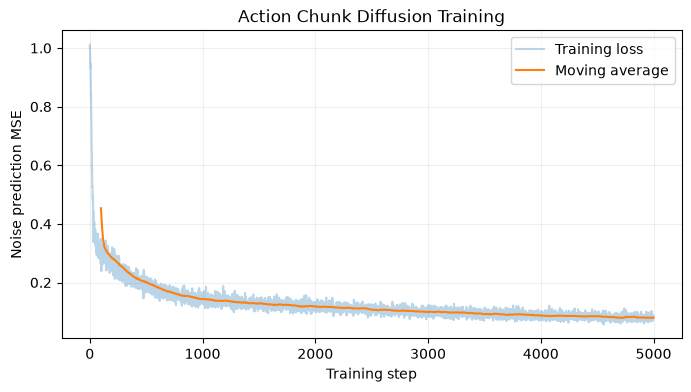

In [44]:
plt.figure(figsize=(8, 4))

plt.plot(
    chunk_losses,
    alpha=0.3,
    label="Training loss",
)

window = 100

smoothed = np.convolve(
    chunk_losses,
    np.ones(window) / window,
    mode="valid",
)

plt.plot(
    np.arange(window - 1, len(chunk_losses)),
    smoothed,
    label="Moving average",
)

plt.xlabel("Training step")
plt.ylabel("Noise prediction MSE")
plt.title("Action Chunk Diffusion Training")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

We have trained a conditional diffusion model to predict noise added
to complete action chunks.

We now use the learned denoising process to generate action sequences
conditioned on a robot observation.

We investigate two properties:

1. **Multimodality:** different samples may represent different valid strategies.
2. **Temporal coherence:** actions within the same chunk should form
   a consistent short-horizon behavior.

Unlike single-action diffusion, the denoiser operates jointly on all
actions in the chunk.

In [45]:
@torch.no_grad()
def chunk_ddpm_sample(
    model,
    observation,
    n_samples=100,
):
    model.eval()

    obs = torch.as_tensor(
        observation,
        dtype=torch.float32,
        device=device,
    ).reshape(1, -1)

    obs = obs.expand(n_samples, -1)

    # Gaussian noise in normalized action-chunk space
    x = torch.randn(
        n_samples,
        H,
        action_dim,
        device=device,
    )

    for k in reversed(range(T)):

        k_batch = torch.full(
            (n_samples,),
            k,
            dtype=torch.long,
            device=device,
        )

        predicted_noise = model(
            x,
            k_batch,
            obs,
        )

        alpha = alphas[k].to(device)
        beta = betas[k].to(device)
        alpha_bar = alpha_bars[k].to(device)

        mean = (
            x
            - beta / torch.sqrt(1 - alpha_bar)
            * predicted_noise
        ) / torch.sqrt(alpha)

        if k > 0:
            alpha_bar_prev = alpha_bars[k - 1].to(device)

            posterior_variance = (
                beta
                * (1 - alpha_bar_prev)
                / (1 - alpha_bar)
            )

            x = (
                mean
                + torch.sqrt(posterior_variance)
                * torch.randn_like(x)
            )
        else:
            x = mean

    # Convert normalized actions to robot action units
    mean = action_mean.to(device).view(1, 1, -1)
    std = action_std.to(device).view(1, 1, -1)

    chunks = x * std + mean

    return chunks.cpu()

In [46]:
generated_chunks = chunk_ddpm_sample(
    chunk_model,
    initial_observation,
    n_samples=1000,
)

print(generated_chunks.shape)

torch.Size([1000, 8, 2])


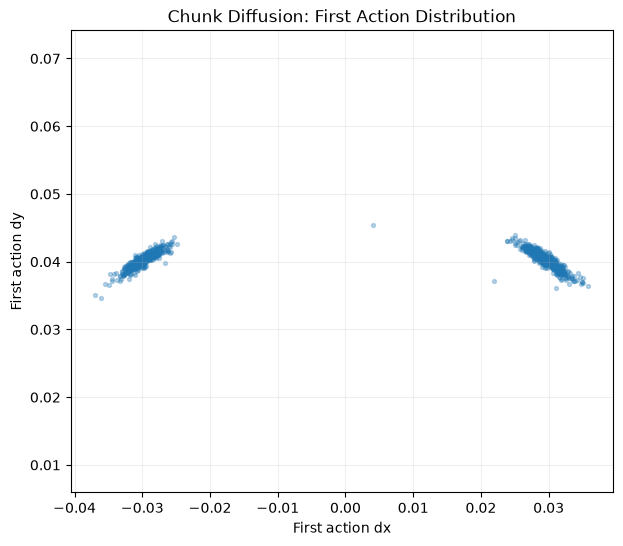

In [47]:
first_actions = generated_chunks[:, 0, :].numpy()

plt.figure(figsize=(7, 6))

plt.scatter(
    first_actions[:, 0],
    first_actions[:, 1],
    s=8,
    alpha=0.3,
)

plt.xlabel("First action dx")
plt.ylabel("First action dy")
plt.title("Chunk Diffusion: First Action Distribution")
plt.axis("equal")
plt.grid(alpha=0.2)
plt.show()

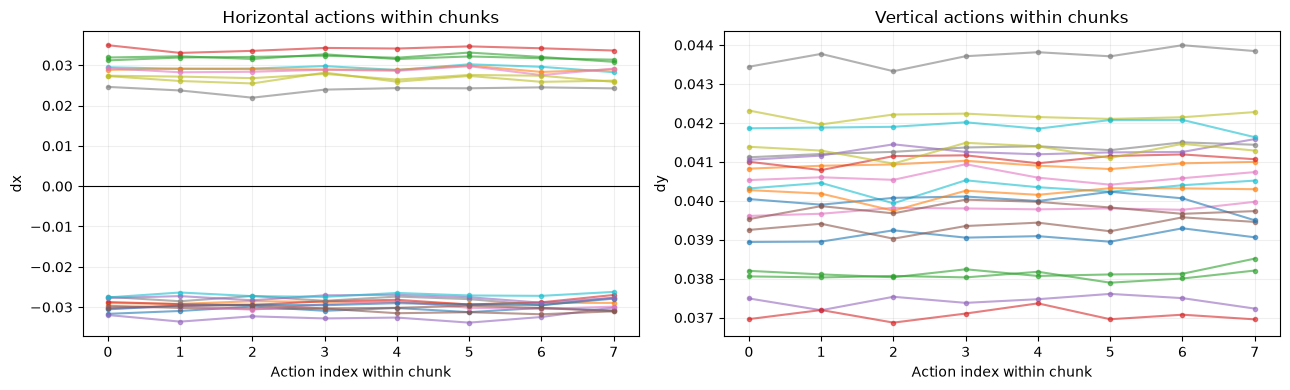

In [48]:
n_plot = 20

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4),
)

for i in range(n_plot):

    chunk = generated_chunks[i].numpy()

    axes[0].plot(
        chunk[:, 0],
        marker=".",
        alpha=0.6,
    )

    axes[1].plot(
        chunk[:, 1],
        marker=".",
        alpha=0.6,
    )

axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Horizontal actions within chunks")
axes[0].set_ylabel("dx")

axes[1].set_title("Vertical actions within chunks")
axes[1].set_ylabel("dy")

for ax in axes:
    ax.set_xlabel("Action index within chunk")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

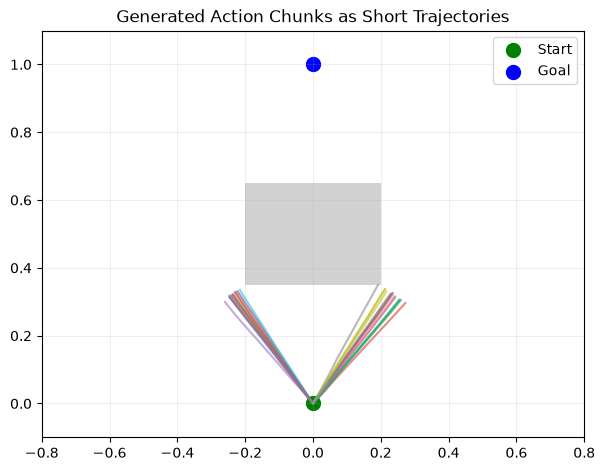

In [49]:
n_plot = 30

start_np = np.asarray(start, dtype=float)

fig, ax = plt.subplots(figsize=(7, 7))

obstacle = Rectangle(
    (-0.2, 0.35),
    0.4,
    0.3,
    facecolor="gray",
    alpha=0.35,
)

ax.add_patch(obstacle)

for i in range(n_plot):

    chunk = generated_chunks[i].numpy()

    positions = np.vstack([
        start_np,
        start_np + np.cumsum(chunk, axis=0),
    ])

    ax.plot(
        positions[:, 0],
        positions[:, 1],
        alpha=0.55,
    )

ax.scatter(
    *start_np,
    color="green",
    s=100,
    label="Start",
)

ax.scatter(
    *goal,
    color="blue",
    s=100,
    label="Goal",
)

ax.set_xlim(-0.8, 0.8)
ax.set_ylim(-0.1, 1.1)
ax.set_aspect("equal")
ax.set_title("Generated Action Chunks as Short Trajectories")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

In [50]:
def count_direction_changes(chunk, threshold=0.005):
    dx = np.asarray(chunk)[:, 0]

    # Ignore small horizontal movements
    signs = np.sign(dx[np.abs(dx) > threshold])

    if len(signs) < 2:
        return 0

    return int(np.sum(signs[1:] != signs[:-1]))


direction_changes = [
    count_direction_changes(chunk.numpy())
    for chunk in generated_chunks
]

print(
    "Mean direction changes:",
    np.mean(direction_changes),
)

print(
    "Chunks with no direction changes:",
    f"{np.mean(np.array(direction_changes) == 0):.1%}",
)

Mean direction changes: 0.0
Chunks with no direction changes: 100.0%


## Closed-loop Evaluation of Chunk Diffusion

We have verified that the diffusion model generates multimodal,
temporally coherent action chunks.

We now evaluate the policy in closed-loop using different
execution horizons.

In [52]:
def rollout_chunk_diffusion(
    start,
    goal,
    execution_horizon=2,
    max_steps=100,
    goal_tolerance=0.05,
):
    assert 1 <= execution_horizon <= H

    position = np.asarray(start, dtype=float).copy()
    goal = np.asarray(goal, dtype=float)

    positions = [position.copy()]
    actions = []

    success = False
    collision = False
    policy_calls = 0

    while len(actions) < max_steps:

        observation = make_observation(position, goal)

        chunk = chunk_ddpm_sample(
            chunk_model,
            observation,
            n_samples=1,
        )[0].numpy()

        policy_calls += 1

        for action in chunk[:execution_horizon]:

            if len(actions) >= max_steps:
                break

            next_position = step(position, action)

            position = np.asarray(
                next_position, dtype=float
            ).copy()

            positions.append(position.copy())
            actions.append(action.copy())

            if is_collision(position):
                collision = True
                break

            if np.linalg.norm(position - goal) < goal_tolerance:
                success = True
                break

        if success or collision:
            break

    return {
        "positions": np.asarray(positions),
        "actions": np.asarray(actions),
        "success": success,
        "collision": collision,
        "policy_calls": policy_calls,
    }

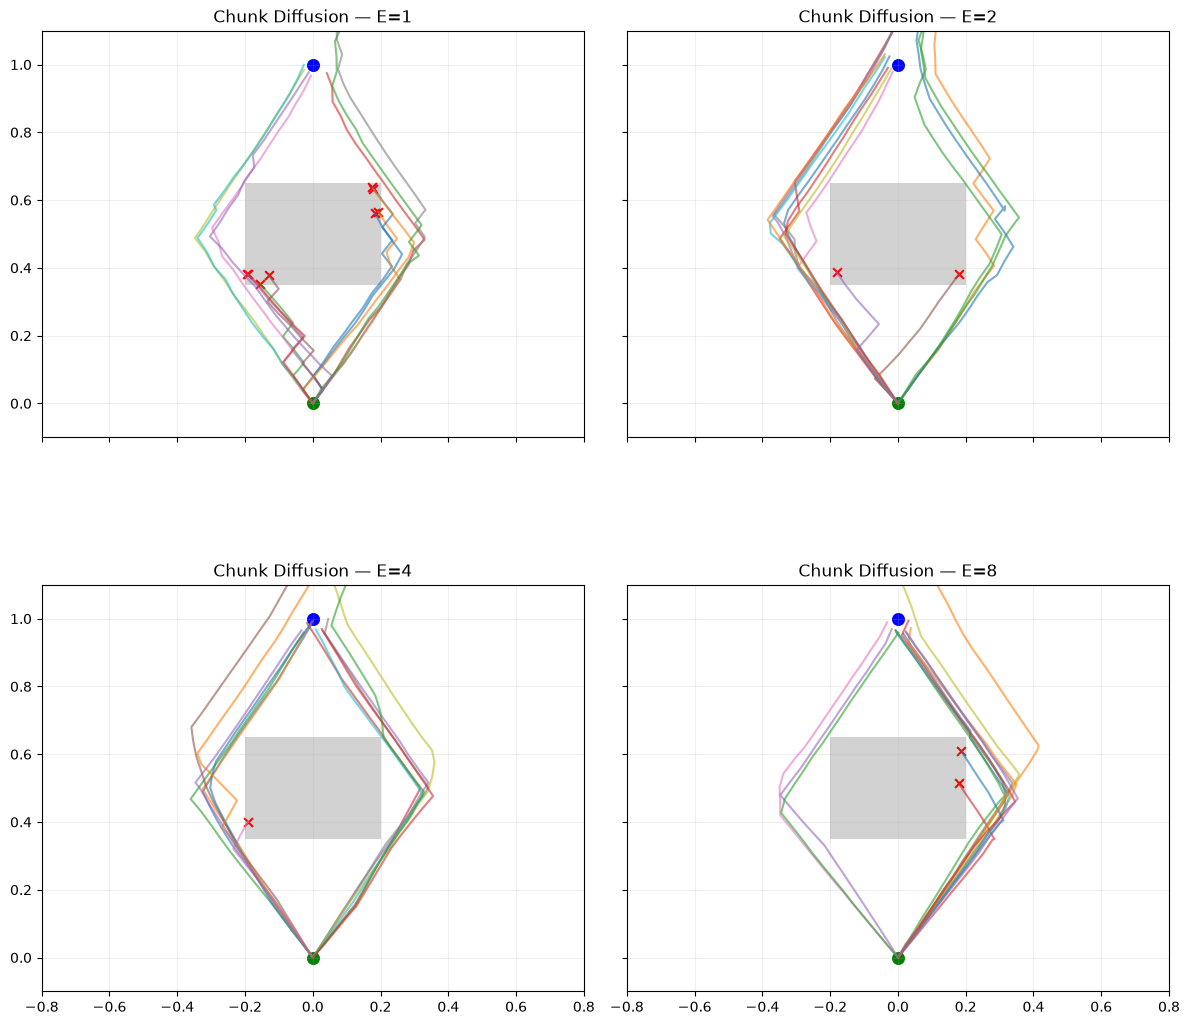

In [53]:
execution_horizons = [1, 2, 4, 8]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 12),
    sharex=True,
    sharey=True,
)

for ax, E in zip(axes.flat, execution_horizons):

    rollouts = [
        rollout_chunk_diffusion(
            start,
            goal,
            execution_horizon=E,
        )
        for _ in range(15)
    ]

    ax.add_patch(
        Rectangle(
            (-0.2, 0.35),
            0.4,
            0.3,
            facecolor="gray",
            alpha=0.35,
        )
    )

    for rollout in rollouts:
        positions = rollout["positions"]

        ax.plot(
            positions[:, 0],
            positions[:, 1],
            alpha=0.6,
        )

        if rollout["collision"]:
            ax.scatter(
                *positions[-1],
                color="red",
                marker="x",
                s=40,
            )

    ax.scatter(*start, color="green", s=70)
    ax.scatter(*goal, color="blue", s=70)

    ax.set_title(f"Chunk Diffusion — E={E}")
    ax.set_xlim(-0.8, 0.8)
    ax.set_ylim(-0.1, 1.1)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [54]:
n_eval = 30

results = {}

for E in execution_horizons:

    evaluations = [
        rollout_chunk_diffusion(
            start,
            goal,
            execution_horizon=E,
        )
        for _ in range(n_eval)
    ]

    success_rate = np.mean([
        r["success"] for r in evaluations
    ])

    collision_rate = np.mean([
        r["collision"] for r in evaluations
    ])

    timeout_rate = np.mean([
        not r["success"] and not r["collision"]
        for r in evaluations
    ])

    mean_policy_calls = np.mean([
        r["policy_calls"] for r in evaluations
    ])

    results[E] = {
        "success": success_rate,
        "collision": collision_rate,
        "timeout": timeout_rate,
        "policy_calls": mean_policy_calls,
    }

    print(
        f"E={E} | "
        f"Success: {success_rate:.1%} | "
        f"Collision: {collision_rate:.1%} | "
        f"Timeout: {timeout_rate:.1%} | "
        f"Policy calls: {mean_policy_calls:.1f}"
    )

E=1 | Success: 10.0% | Collision: 63.3% | Timeout: 26.7% | Policy calls: 37.2
E=2 | Success: 53.3% | Collision: 20.0% | Timeout: 26.7% | Policy calls: 21.3
E=4 | Success: 60.0% | Collision: 6.7% | Timeout: 33.3% | Policy calls: 12.3
E=8 | Success: 66.7% | Collision: 13.3% | Timeout: 20.0% | Policy calls: 5.2


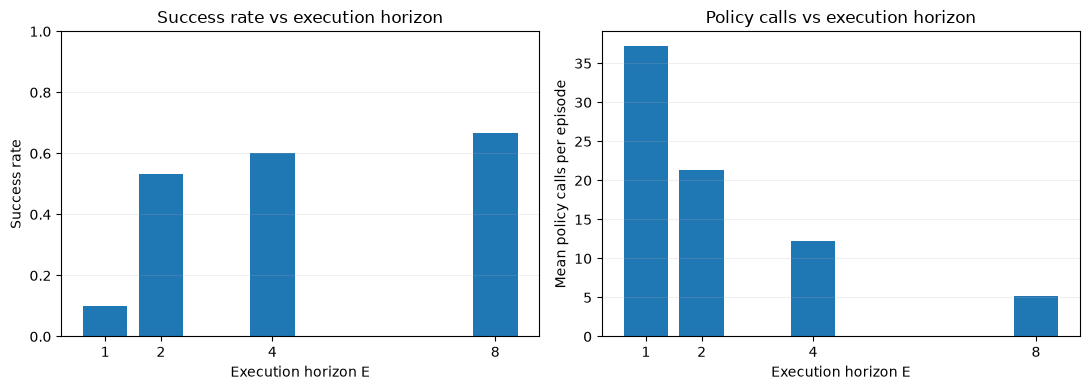

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

success_rates = [
    results[E]["success"] for E in execution_horizons
]

policy_calls = [
    results[E]["policy_calls"] for E in execution_horizons
]

axes[0].bar(execution_horizons, success_rates)
axes[0].set_title("Success rate vs execution horizon")
axes[0].set_xlabel("Execution horizon E")
axes[0].set_ylabel("Success rate")
axes[0].set_ylim(0, 1)

axes[1].bar(execution_horizons, policy_calls)
axes[1].set_title("Policy calls vs execution horizon")
axes[1].set_xlabel("Execution horizon E")
axes[1].set_ylabel("Mean policy calls per episode")

for ax in axes:
    ax.set_xticks(execution_horizons)
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

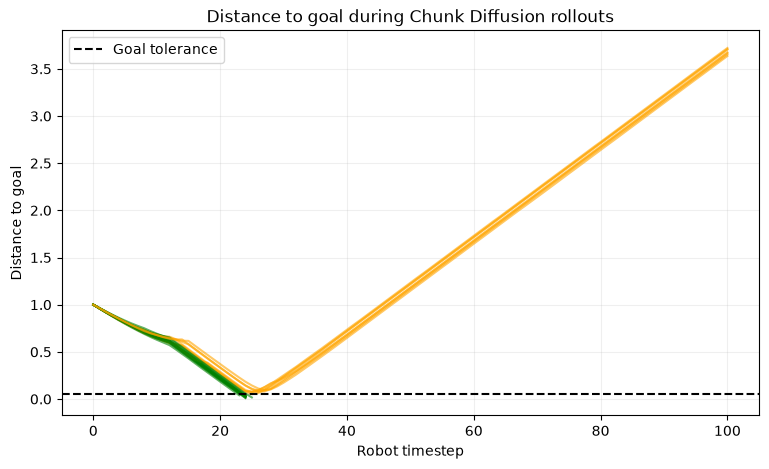

In [56]:
E = 4

eval_rollouts = [
    rollout_chunk_diffusion(
        start,
        goal,
        execution_horizon=E,
    )
    for _ in range(20)
]

fig, ax = plt.subplots(figsize=(9, 5))

for r in eval_rollouts:
    positions = r["positions"]

    distances = np.linalg.norm(
        positions - np.asarray(goal),
        axis=1,
    )

    color = (
        "green" if r["success"]
        else "red" if r["collision"]
        else "orange"
    )

    ax.plot(
        distances,
        color=color,
        alpha=0.6,
    )

ax.axhline(
    0.05,
    color="black",
    linestyle="--",
    label="Goal tolerance",
)

ax.set_xlabel("Robot timestep")
ax.set_ylabel("Distance to goal")
ax.set_title("Distance to goal during Chunk Diffusion rollouts")
ax.grid(alpha=0.2)
ax.legend()

plt.show()

## Conclusions

In this notebook, we implemented a **Denoising Diffusion Probabilistic Model (DDPM)** from scratch and progressively extended it into a conditional robot policy.

### Key takeaways

1. **Diffusion models are generative models.** They learn to generate samples from complex distributions through iterative denoising, starting from Gaussian noise.

2. **Noise prediction enables multimodal generation.** Although the denoiser is trained using MSE, iterative reverse diffusion can generate multiple distinct modes without explicitly specifying their number.

3. **Conditioning turns a generative model into a robot policy.** By providing robot observations to the denoiser, we learn a distribution of actions conditioned on the current state.

4. **Action chunking captures temporal dependencies.** Generating complete action sequences produces coherent short-horizon behaviors, but does not guarantee consistency between successive chunks.

5. **Closed-loop evaluation is essential.** Plausible action distributions do not necessarily translate into successful robot trajectories. Execution horizon, replanning frequency, dataset coverage, and termination behavior all affect performance.

6. **Inference latency matters.** DDPM sampling requires multiple neural network evaluations, motivating action chunking, faster samplers, and alternative generative approaches.

### Limitations

Our implementation uses a simple MLP, a fixed observation representation, a basic DDPM sampler, and a toy PointRobot environment.

The policy sometimes overshoots the goal, highlighting the importance of termination behavior and sufficient demonstration coverage.

### Next: Flow Matching

In the next notebook, we will study **Flow Matching**, a generative approach that learns a continuous velocity field to transport samples from a simple distribution to a complex data distribution.

We will compare its mathematical formulation, training objective, sampling procedure, and inference cost with DDPM before extending it to conditional action generation.